# 41 - Boletim diário: previsão de alertas e de turbidez

| | |
|---|---|
| **Objetivo** | Ver a previsão de hoje e emitir o boletim |
| **O que faz** | Vai buscar as previsões do dia, verifica-as, calcula os níveis de alerta e a turbidez esperada, e escreve o boletim |
| **Usa** | Internet (poucos KB); os limites e os modelos do notebook 40 |
| **Produz** | `data/processed/forecast/latest/` (boletim e tabelas) e uma cópia em `archive/<data>/` |

Em produção isto corre sozinho todos os dias com
`python scripts/run_daily_forecast.py`. Este notebook faz o mesmo e mostra os
gráficos.

**Regra de segurança.** Se os dados do dia não chegarem ou vierem com erros, o
boletim diz "previsão indisponível". Nunca mostra verde por falta de dados. Se
não houver ligação, reutiliza a última previsão guardada e avisa que é uma cópia.

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config" / "config.yaml").exists())
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from ete import alerts, config, drivers, forecast, forecast_models, operations, rasters
from ete import grid as G

cfg = config.load_config()
F = cfg["forecast"]
REPORTS = config.path(cfg, "reports", "producao")
LEVEL_COLOURS = {0: "#2ecc71", 1: "#f1c40f", 2: "#e67e22", 3: "#c0392b"}
pd.set_option("display.float_format", "{:,.2f}".format)

from IPython.display import Markdown, display

## 1. Correr a previsão de hoje

In [2]:
result = operations.run_daily(cfg)            # sem internet: operations.run_daily(cfg, offline=True)
status = result["status"]
print(f"estado: {status['estado']} | fonte: {status['fonte']} | dados com {status['idade_dos_dados_horas']} h | cenários: {status.get('cenarios')}")
for problem in status["problemas"]:
    print("aviso:", problem)

estado: ok | fonte: online | dados com -0.1 h | cenários: 51


## 2. O boletim

In [3]:
display(Markdown(result["bulletin"]))

# Boletim ETE - Rio Incomáti, Marracuene

**Emitido:** 2026-10-11 13:15 UTC · **Válido até:** 21/10

## Nível VERDE nos próximos 10 dias: nenhum cenário prevê cheia no Incomáti em Marracuene.

**O que fazer:** Sem sinais de cheia nos próximos dias. Não é precisa nenhuma ação especial.

## Previsão para os próximos dias

| Dia | Alerta | Alerta possível | Caudal previsto (m³/s) | Cenários acima do limite laranja | Chuva 7 dias na bacia (mm) |
|---|---|---|---|---|---|
| 11/10 | verde | verde | 11 (11 a 11) | 0 % | 8 |
| 12/10 | verde | verde | 9 (9 a 9) | 0 % | 7 |
| 13/10 | verde | verde | 7 (7 a 7) | 0 % | 2 |
| 14/10 | verde | verde | 5 (5 a 5) | 0 % | 1 |
| 15/10 | verde | verde | 4 (4 a 4) | 0 % | 1 |
| 16/10 | verde | verde | 4 (4 a 4) | 0 % | 1 |
| 17/10 | verde | verde | 3 (3 a 3) | 0 % | 0 |
| 18/10 | verde | verde | 3 (3 a 3) | 0 % | 0 |
| 19/10 | verde | verde | 2 (2 a 2) | 0 % | 1 |
| 20/10 | verde | verde | 2 (2 a 2) | 0 % | 2 |
| 21/10 | verde | verde | 2 (2 a 2) | 0 % | 2 |

Limites de caudal: amarelo 164, laranja 376, vermelho 970 m³/s. "Alerta" é o nível previsto por pelo menos metade dos 51 cenários; "alerta possível" por pelo menos 20 %.

**Segunda opinião (modelo próprio, só com a chuva já caída):** 12/10: 9, 13/10: 7, 14/10: 6, 16/10: 5, 18/10: 5 m³/s.

## Qualidade da água: turbidez (cor da água vista por satélite)

| Troço do rio | Estado nos últimos 20 dias | Manhãs com água mais turva nos próximos 10 dias | Dias mais prováveis |
|---|---|---|---|
| 1 montante (norte) | normal (2 imagens) | sem previsão (medição pouco fiável neste troço) | - |
| 2 troço médio | elevada (2 imagens) | 0 (possível) | - |
| 3 jusante | elevada (1 imagens) | 1 (provável) | 11/10 |
| 4 foz / estuário | normal (1 imagens) | 1 (provável) | 11/10 |

A previsão parte da última medição por satélite (09/10). É para a manhã (cerca das 9h30), a hora a que os satélites observam o rio. A cor da água muda com o caudal e também com a maré, por isso varia de dia para dia mesmo sem chuva. "Mais turva" quer dizer entre os 25 % de dias mais turvos desse troço.

A água do rio deve ser sempre tratada antes de beber (ferver, ou cloro). Com turbidez elevada, deixe primeiro a água assentar e filtre-a por um pano limpo: a água barrenta é mais difícil de desinfetar.

## Confiança e limites

- Previsão de caudal: 51 cenários do GloFAS; dados obtidos em 2026-10-11 13:19 UTC.
- A chuva prevista só é usada como gatilho até 7 dias à frente.
- Turbidez: índice de cor da água (NDTI) medido por satélite; dois satélites independentes concordam (correlação 0,92 no mesmo dia). A previsão dá maior probabilidade ao dia turvo em cerca de 9 de cada 10 comparações entre um dia turvo e um dia normal (AUC 0,87, em anos que o modelo não viu; 0,88 noutro satélite e noutros anos). É um indicador relativo: não há medições no rio para o converter em unidades de turbidez.
- Os limites dos alertas foram calculados com dados até 2021 e testados em 2022-2026.

*Boletim experimental do projeto Eyes to Earth. Não substitui os avisos oficiais do INGD, do INAM e da ARA-Sul. A turbidez é um indicador da cor da água visto por satélite: não mede se a água é segura.*


## 3. A previsão em gráficos

- **Em cima:** cada linha fina é um dos 51 cenários de caudal; a linha grossa é a
  mediana. As linhas tracejadas são os limites dos níveis. Os pontos são a
  segunda opinião do nosso Modelo C.
- **No meio:** a chuva na bacia, observada (cinzento) e prevista (azul).
- **Em baixo:** o nível de alerta de cada dia; a faixa de cima é o mais provável
  e a de baixo o possível.

,dias_a_frente,caudal_mediana,caudal_p10,caudal_p90,prob_laranja,chuva_7d_mm,alerta,alerta_possivel,caudal_modelo_c
date,,,,,,,,,
2026-10-11,0,11.10,11.00,11.10,0.00,7.90,verde,verde,NaN
2026-10-12,1,8.80,8.80,8.80,0.00,7.30,verde,verde,9.00
2026-10-13,2,7.00,6.90,7.00,0.00,2.00,verde,verde,7.40
2026-10-14,3,5.40,5.40,5.50,0.00,0.90,verde,verde,6.20
2026-10-15,4,4.40,4.40,4.50,0.00,0.90,verde,verde,NaN
2026-10-16,5,3.80,3.70,3.80,0.00,0.90,verde,verde,5.30
2026-10-17,6,3.20,3.10,3.30,0.00,0.40,verde,verde,NaN
2026-10-18,7,2.70,2.70,2.80,0.00,0.40,verde,verde,5.00
2026-10-19,8,2.30,2.30,2.40,0.00,1.00,verde,verde,NaN


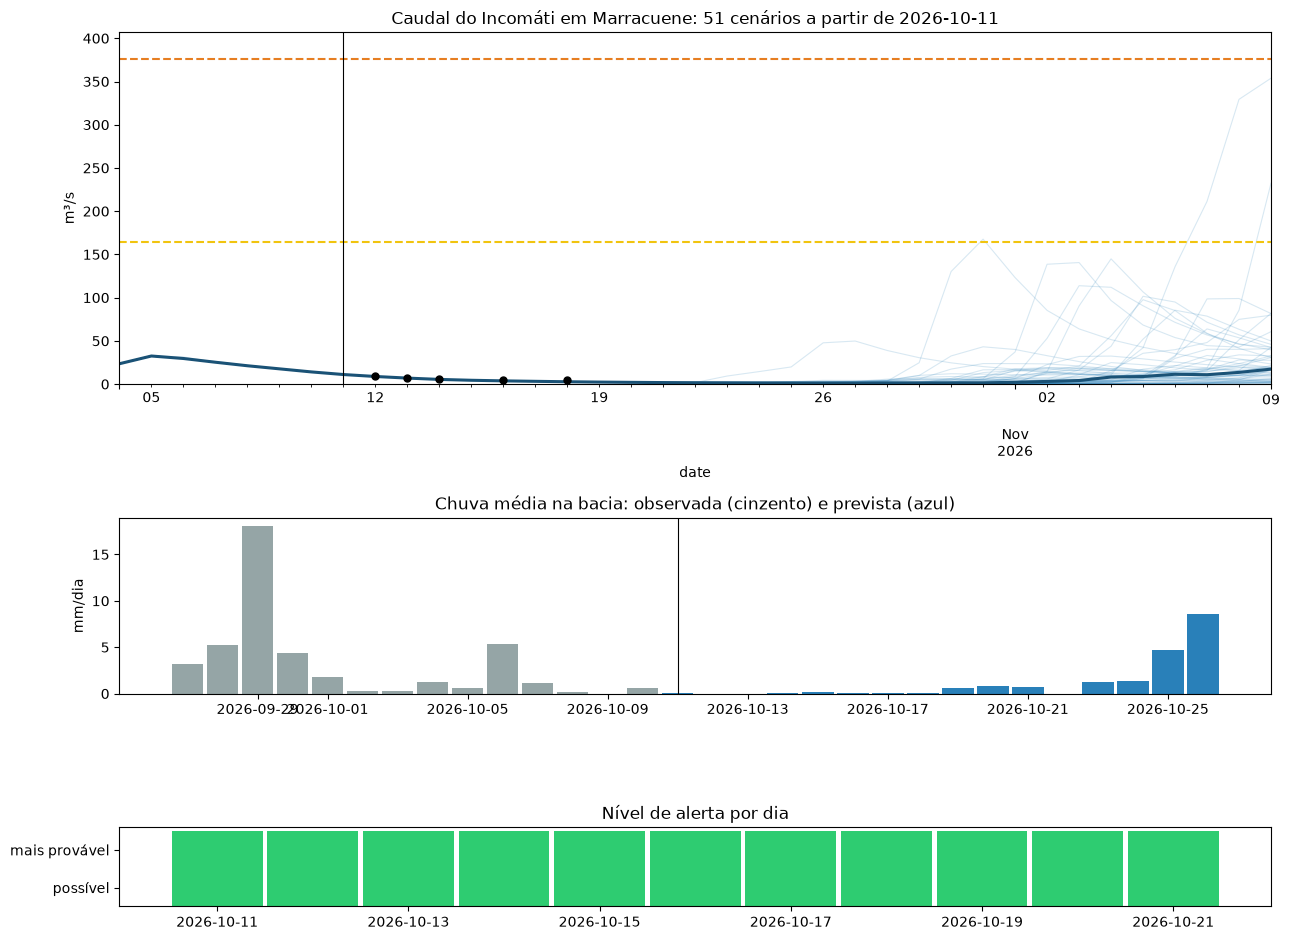

In [4]:
fc, outlook = result["forecast"], result["outlook"]
limits = forecast.load_limits(cfg)
today = pd.Timestamp(fc["date"])
q = fc["discharge"].loc[today - pd.Timedelta(days=7):today + pd.Timedelta(days=F["ensemble_days"] - 1)]

fig, axes = plt.subplots(3, 1, figsize=(13, 9.5), height_ratios=[4, 2, 0.9])
q.plot(ax=axes[0], color="#2980b9", alpha=0.18, linewidth=0.8, legend=False)
q.median(axis=1).plot(ax=axes[0], color="#1a5276", linewidth=2.2)
if outlook["caudal_modelo_c"].notna().any():
    outlook["caudal_modelo_c"].dropna().plot(ax=axes[0], style="o", color="black", markersize=5)
top = max(float(q.max().max()) * 1.15, limits["discharge_m3s"]["amarelo"] * 1.3)
for name, value in limits["discharge_m3s"].items():
    if value <= top * 1.5:
        axes[0].axhline(value, color={"amarelo": "#f1c40f", "laranja": "#e67e22", "vermelho": "#c0392b"}[name], linestyle="--")
axes[0].axvline(today, color="black", linewidth=0.8); axes[0].set_ylim(0, top); axes[0].set_ylabel("m³/s")
axes[0].set_title(f"Caudal do Incomáti em Marracuene: 51 cenários a partir de {today.date()}")

rain = fc["rain"].loc[today - pd.Timedelta(days=14):]
axes[1].bar(rain.index, rain, color=["#95a5a6" if d < today else "#2980b9" for d in rain.index], width=0.9)
axes[1].axvline(today, color="black", linewidth=0.8); axes[1].set_ylabel("mm/dia"); axes[1].set_title("Chuva média na bacia: observada (cinzento) e prevista (azul)")

for row, col in enumerate(["nivel", "nivel_possivel"]):
    axes[2].bar(outlook.index, 1, bottom=1 - row, width=0.95, color=[LEVEL_COLOURS[int(v)] for v in outlook[col]])
axes[2].set_yticks([0.5, 1.5], ["possível", "mais provável"]); axes[2].set_title("Nível de alerta por dia")
plt.tight_layout(); plt.savefig(config.path(cfg, "forecast", "latest") / "previsao.png", dpi=110)
outlook[["dias_a_frente", "caudal_mediana", "caudal_p10", "caudal_p90", "prob_laranja", "chuva_7d_mm", "alerta", "alerta_possivel", "caudal_modelo_c"]].round(1)

## 4. Turbidez: última medição e o que esperar

A tabela mostra, para cada troço, o estado nos últimos 20 dias (mediana das
imagens que viram pelo menos metade do troço) e a previsão para as manhãs dos
próximos dias, feita com o caudal previsto, a maré e a última medição por
satélite (coluna `medicao_usada`). Usa-se a mediana de várias imagens porque uma imagem sozinha oscila com
a maré, a bruma e as nuvens. As medições são atualizadas com
`python scripts/update_water_quality_scenes.py` (uma vez por semana chega).

,estado,medicoes_em_20_dias,ultima_medicao,fiabilidade,medicao_usada,dias_elevada,prob_max,dia_prob_max,previsao
troco,,,,,,,,,
1 montante (norte),normal,2,2026-09-26,reduzida,,-1,NaN,,sem previsão
2 troço médio,elevada,2,2026-10-09,boa,2026-10-09,0,0.35,2026-10-13,possível
3 jusante,elevada,1,2026-09-24,boa,2026-10-09,1,0.58,2026-10-11,provável
4 foz / estuário,normal,1,2026-09-24,boa,2026-10-09,1,0.60,2026-10-11,provável


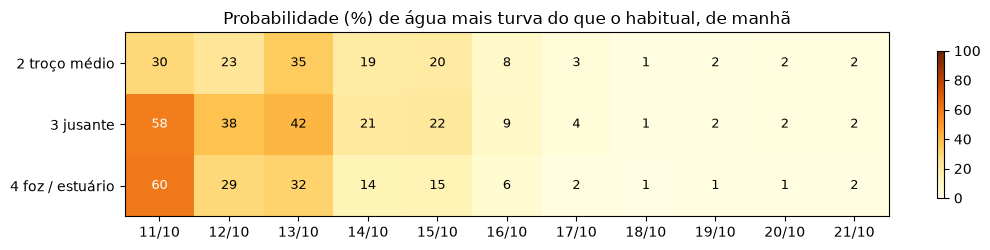

In [5]:
turbidity = result["turbidity"]
daily = turbidity.attrs["daily"]
if len(daily.columns):
    fig, ax = plt.subplots(figsize=(11, 2.6))
    im = ax.imshow(100 * daily.T.values, cmap="YlOrBr", vmin=0, vmax=100, aspect="auto")
    ax.set_yticks(range(len(daily.columns)), daily.columns); ax.set_xticks(range(len(daily)), daily.index.strftime("%d/%m"))
    for (i, j), v in np.ndenumerate(100 * daily.T.values):
        ax.text(j, i, f"{v:.0f}", ha="center", va="center", color="white" if v > 55 else "black", fontsize=9)
    ax.set_title("Probabilidade (%) de água mais turva do que o habitual, de manhã"); plt.colorbar(im, ax=ax, shrink=0.8)
    plt.tight_layout(); plt.savefig(config.path(cfg, "forecast", "latest") / "turbidez.png", dpi=110)
turbidity[["estado", "medicoes_em_20_dias", "ultima_medicao", "fiabilidade", "medicao_usada", "dias_elevada", "prob_max", "dia_prob_max", "previsao"]].round(2)

## 5. As previsões anteriores acertaram?

Compara as previsões guardadas nos dias anteriores com o caudal que o serviço
depois deu como observado. A tabela fica vazia nos primeiros dias de operação e
vai-se enchendo. É a partir dela que se saberá, ao fim de uma época chuvosa, com
quantos dias de antecedência a previsão é fiável neste rio.

In [6]:
checked = operations.verification(cfg)
if checked.empty:
    print("ainda não há previsões antigas suficientes para verificar (são precisos alguns dias de operação)")
else:
    resumo = checked.groupby("dias_a_frente").agg(previsoes=("erro", "size"), erro_medio_m3s=("erro", "mean"),
                                                  erro_absoluto_m3s=("erro", lambda e: e.abs().mean()),
                                                  dentro_do_intervalo=("dentro_do_intervalo", "mean"),
                                                  nivel_certo=("nivel_previsto", lambda s: (s == checked.loc[s.index, "nivel_observado"]).mean()))
    display(resumo.round(2))

ainda não há previsões antigas suficientes para verificar (são precisos alguns dias de operação)


## Ficheiros para a plataforma

| Ficheiro em `data/processed/forecast/latest/` | Para quê |
|---|---|
| `boletim.json` | tudo o que o boletim diz, pronto para a app |
| `boletim.md` | o boletim em texto |
| `previsao_alertas.csv` | nível de alerta e caudal por dia |
| `cenarios_caudal.csv` | os 51 cenários |
| `chuva_bacia.csv` | chuva observada e prevista |
| `turbidez.csv`, `turbidez_diaria.csv` | por troço: estado medido e previsão; probabilidade por dia |
| `estado.json` | hora dos dados, se estão atualizados, problemas encontrados |

A app deve ler sempre o `estado.json` primeiro: se `estado` não for `ok`, mostra
o aviso em vez do mapa de alerta.